# LAB 2 – Khai phá dữ liệu: Bài 5 (Trang 26, 27)
## Phân lớp bệnh tim Heart Disease (ID3, CART, Naive Bayes)

**Sinh viên:** Nguyễn Khánh Hà – 6451071022


In [1]:
DATA_PATH = "heart.csv"   # dữ liệu Heart Disease
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
print("Nguyễn Khánh Hà - 6451071022")

Nguyễn Khánh Hà - 6451071022


## Câu a): Nhập dữ liệu, xóa các dòng dữ liệu trống và đổi tên các cột

In [2]:
print("Nguyễn Khánh Hà - 6451071022")
df = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")
print("Kích thước dữ liệu ban đầu:", df.shape)
print("Tên cột ban đầu:", list(df.columns))
print("Số giá trị trống mỗi cột:\n", df.isna().sum())

# Xóa các dòng chứa dữ liệu trống
df = df.dropna()
print("\nKích thước dữ liệu sau khi xóa dòng trống:", df.shape)

# Đổi tên các cột theo yêu cầu của đề
df.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
              'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
              'exercise_induced_angina', 'st_depression', 'st_slope',
              'num_major_vessels', 'thalassemia', 'target']
print("Tên cột sau khi đổi:", list(df.columns))
print("\nPhân bố thuộc tính quyết định 'target':\n", df["target"].value_counts().sort_index())
df.head()

Nguyễn Khánh Hà - 6451071022
Kích thước dữ liệu ban đầu: (303, 14)
Tên cột ban đầu: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Số giá trị trống mỗi cột:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Kích thước dữ liệu sau khi xóa dòng trống: (303, 14)
Tên cột sau khi đổi: ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']

Phân bố thuộc tính quyết định 'target':
 target
0    138
1    165
Name: count, dtype: int64


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


**Kết luận:** Không có dòng dữ liệu trống nên không xóa dòng nào (303 dòng giữ nguyên). Đã đổi tên 14 cột theo danh sách của đề.

## Câu 3: Khảo sát độ tương đồng giữa các cột bằng hệ số Pearson
Cột nào có giá trị tương đồng cao (|r| > 0.8) thì loại bỏ (không xét thuộc tính quyết định `target`).

Nguyễn Khánh Hà - 6451071022
                          age   sex  chest_pain_type  resting_blood_pressure  cholesterol  fasting_blood_sugar  rest_ecg  max_heart_rate_achieved  exercise_induced_angina  st_depression  st_slope  num_major_vessels  thalassemia  target
age                      1.00 -0.10            -0.07                    0.28         0.21                 0.12     -0.12                    -0.40                     0.10           0.21     -0.17               0.28         0.07   -0.23
sex                     -0.10  1.00            -0.05                   -0.06        -0.20                 0.05     -0.06                    -0.04                     0.14           0.10     -0.03               0.12         0.21   -0.28
chest_pain_type         -0.07 -0.05             1.00                    0.05        -0.08                 0.09      0.04                     0.30                    -0.39          -0.15      0.12              -0.18        -0.16    0.43
resting_blood_pressure   0.

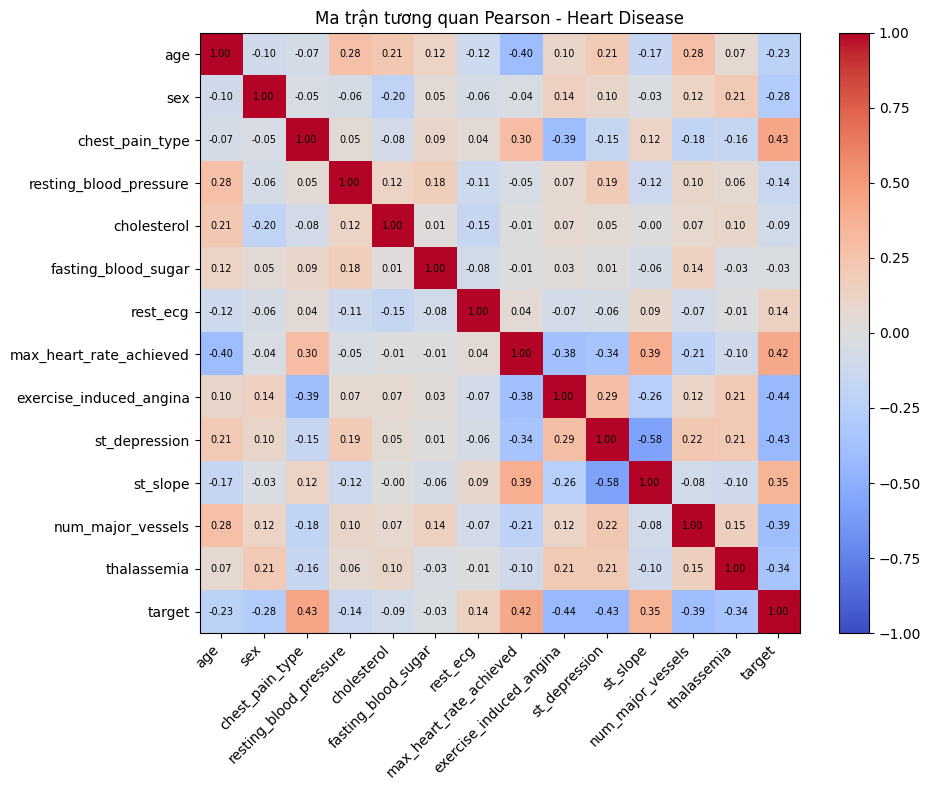


Các cột có |r| > 0.8 cần loại bỏ: không có
Cặp tương quan cao nhất giữa các thuộc tính: 0.58
Kích thước dữ liệu sau khi loại: (303, 14)


In [3]:
print("Nguyễn Khánh Hà - 6451071022")
THRESHOLD = 0.8
corr = df.corr(method="pearson")
print(corr.round(2).to_string())

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Ma trận tương quan Pearson - Heart Disease")
plt.tight_layout()
plt.show()

feat_corr = corr.drop(index="target", columns="target").abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > THRESHOLD).any()]
print(f"\nCác cột có |r| > {THRESHOLD} cần loại bỏ:", to_drop if to_drop else "không có")
print("Cặp tương quan cao nhất giữa các thuộc tính:", round(upper.max().max(), 2))
df = df.drop(columns=to_drop)
print("Kích thước dữ liệu sau khi loại:", df.shape)

**Kết luận:** Không loại cột nào (tương quan cao nhất giữa các thuộc tính chỉ 0.58)

## Câu 4: Tách dữ liệu thành thuộc tính bình thường và thuộc tính quyết định (`target`)

In [4]:
print("Nguyễn Khánh Hà - 6451071022")
X = df.drop(columns="target")   # thuộc tính bình thường
y = df["target"]                # thuộc tính quyết định
print("X:", X.shape, "| y:", y.shape)
X.head()

Nguyễn Khánh Hà - 6451071022
X: (303, 13) | y: (303,)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Dữ liệu Heart Disease chỉ gồm các cột số nên không có cột nào cần chuyển đổi.

In [5]:
print("Nguyễn Khánh Hà - 6451071022")
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Các cột không phải dạng số:", cat_cols if cat_cols else "không có")
print("Kiểu dữ liệu các cột:\n", X.dtypes)

if cat_cols:                       # chỉ chuyển đổi khi có cột dạng chữ
    X = pd.get_dummies(X, columns=cat_cols, dtype=int)
print("\nSố cột của X:", X.shape[1])

Nguyễn Khánh Hà - 6451071022
Các cột không phải dạng số: không có
Kiểu dữ liệu các cột:
 age                          int64
sex                          int64
chest_pain_type              int64
resting_blood_pressure       int64
cholesterol                  int64
fasting_blood_sugar          int64
rest_ecg                     int64
max_heart_rate_achieved      int64
exercise_induced_angina      int64
st_depression              float64
st_slope                     int64
num_major_vessels            int64
thalassemia                  int64
dtype: object

Số cột của X: 13


**Kết luận:** Không có cột dạng chữ

## Câu 6: Tách dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)
Đề không cho sẵn câu lệnh chia dữ liệu ở bài này, nên dùng cùng cách chia như Bài 4 và Bài 6.

In [6]:
print("Nguyễn Khánh Hà - 6451071022")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Nguyễn Khánh Hà - 6451071022
X_train: (212, 13) | y_train: (212,)
X_test : (91, 13) | y_test : (91,)


## Câu 7: Xây dựng cây ID3 (criterion = entropy), ma trận nhầm lẫn và biểu diễn cây

Nguyễn Khánh Hà - 6451071022
Classification report - ID3:

                precision    recall  f1-score   support

Không bệnh (0)       0.64      0.71      0.67        41
   Có bệnh (1)       0.74      0.68      0.71        50

      accuracy                           0.69        91
     macro avg       0.69      0.69      0.69        91
  weighted avg       0.70      0.69      0.69        91

Confusion matrix:
 [[29 12]
 [16 34]]


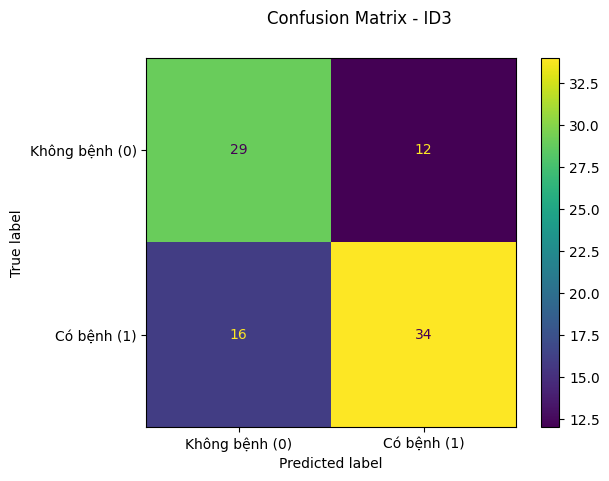

In [7]:
print("Nguyễn Khánh Hà - 6451071022")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Classification report - ID3:\n")
print(metrics.classification_report(y_test, pred_id3, target_names=["Không bệnh (0)", "Có bệnh (1)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(id3, X_test, y_test, display_labels=["Không bệnh (0)", "Có bệnh (1)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - ID3")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


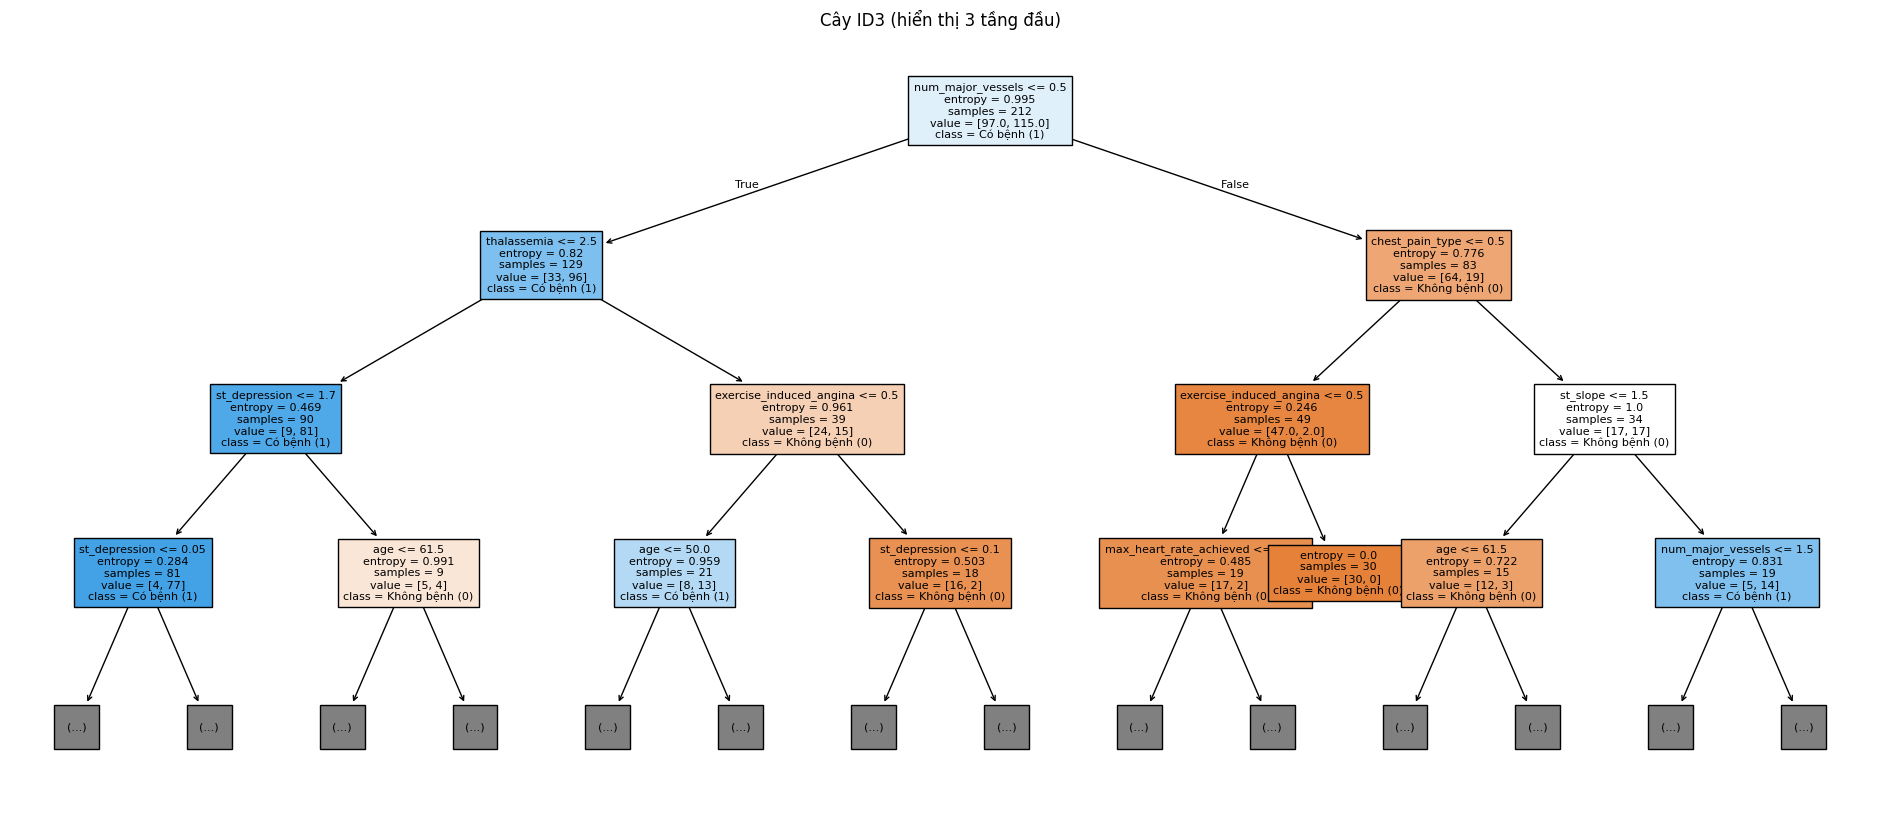

Độ sâu thực tế của cây: 7 | Số lá: 33


In [8]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây đầy đủ khá lớn nên chỉ vẽ 3 tầng đầu để dễ nhìn
plt.figure(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=X.columns, class_names=["Không bệnh (0)", "Có bệnh (1)"],
               filled=True, fontsize=8)
plt.title("Cây ID3 (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", id3.get_depth(), "| Số lá:", id3.get_n_leaves())

## Câu 8: Lặp lại Câu 7 với cây CART (criterion = gini)

Nguyễn Khánh Hà - 6451071022
Classification report - CART:

                precision    recall  f1-score   support

Không bệnh (0)       0.68      0.78      0.73        41
   Có bệnh (1)       0.80      0.70      0.74        50

      accuracy                           0.74        91
     macro avg       0.74      0.74      0.74        91
  weighted avg       0.74      0.74      0.74        91

Confusion matrix:
 [[32  9]
 [15 35]]


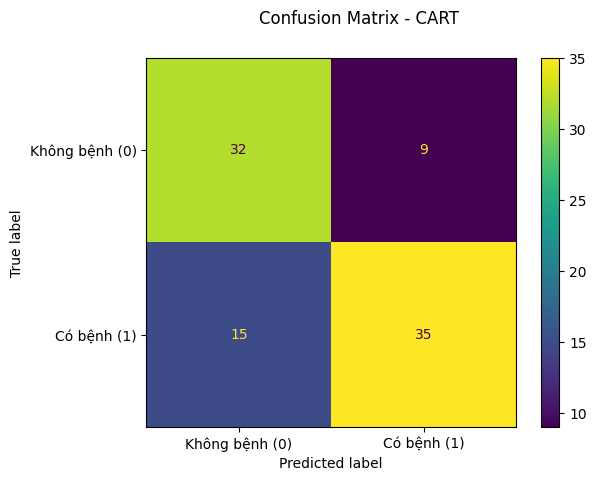

In [9]:
print("Nguyễn Khánh Hà - 6451071022")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Classification report - CART:\n")
print(metrics.classification_report(y_test, pred_cart, target_names=["Không bệnh (0)", "Có bệnh (1)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(cart, X_test, y_test, display_labels=["Không bệnh (0)", "Có bệnh (1)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - CART")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


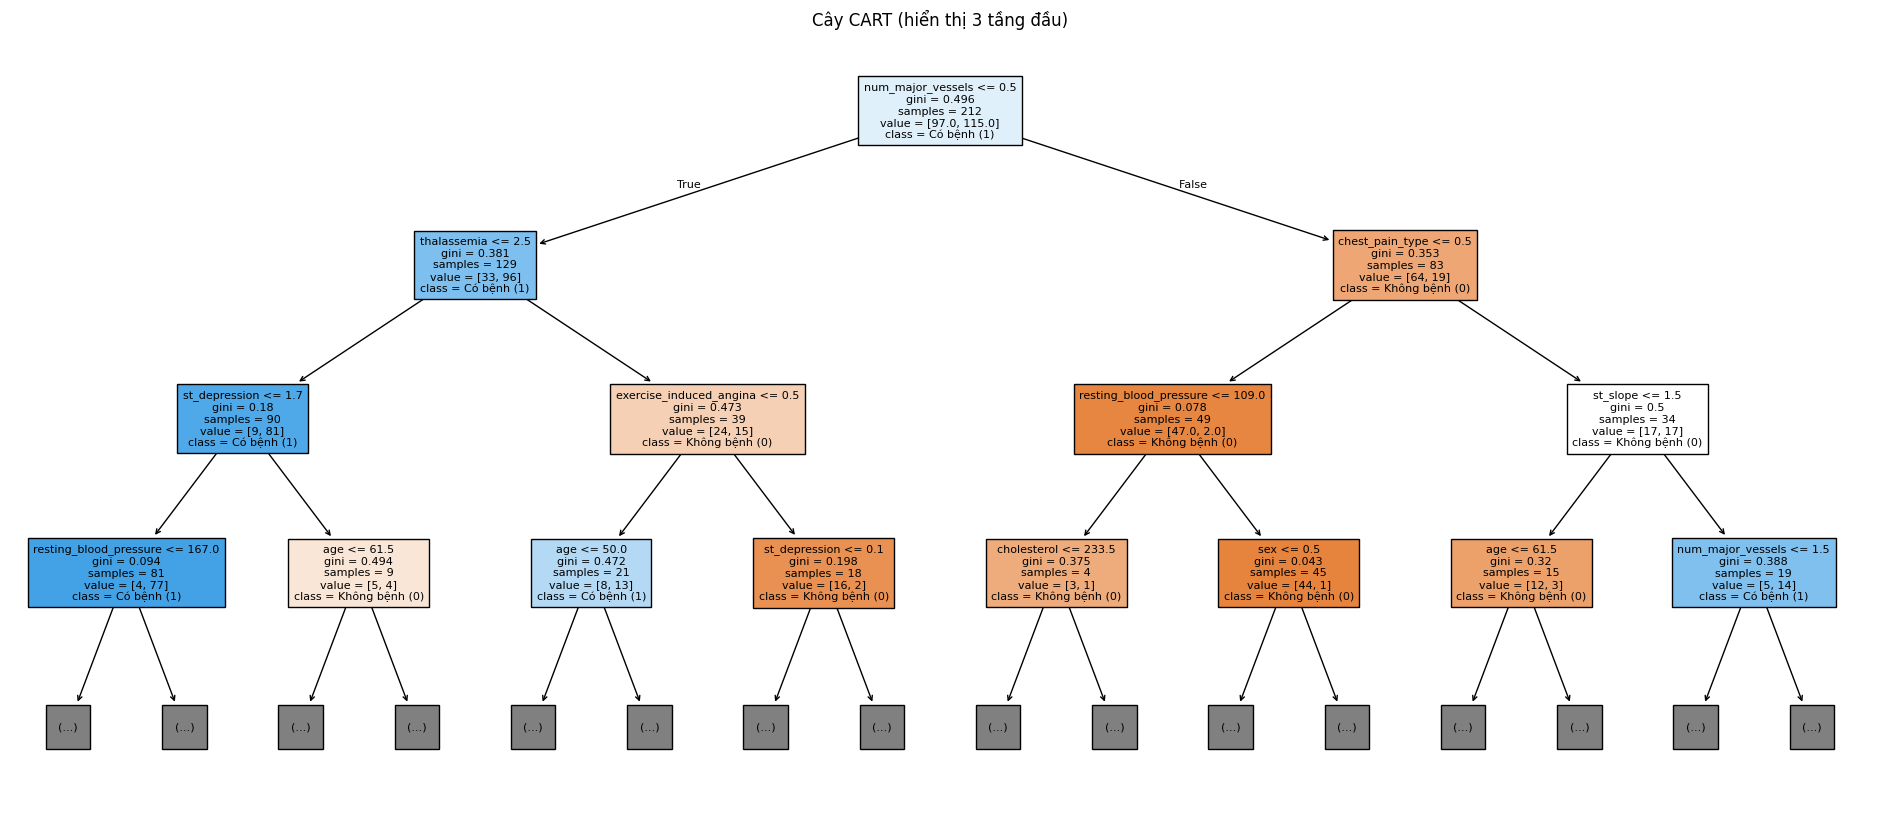

Độ sâu thực tế của cây: 9 | Số lá: 37


In [10]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây đầy đủ khá lớn nên chỉ vẽ 3 tầng đầu để dễ nhìn
plt.figure(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=X.columns, class_names=["Không bệnh (0)", "Có bệnh (1)"],
               filled=True, fontsize=8)
plt.title("Cây CART (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", cart.get_depth(), "| Số lá:", cart.get_n_leaves())

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Nguyễn Khánh Hà - 6451071022
Classification report - Naïve Bayes:

                precision    recall  f1-score   support

Không bệnh (0)       0.78      0.88      0.83        41
   Có bệnh (1)       0.89      0.80      0.84        50

      accuracy                           0.84        91
     macro avg       0.84      0.84      0.83        91
  weighted avg       0.84      0.84      0.84        91

Confusion matrix:
 [[36  5]
 [10 40]]


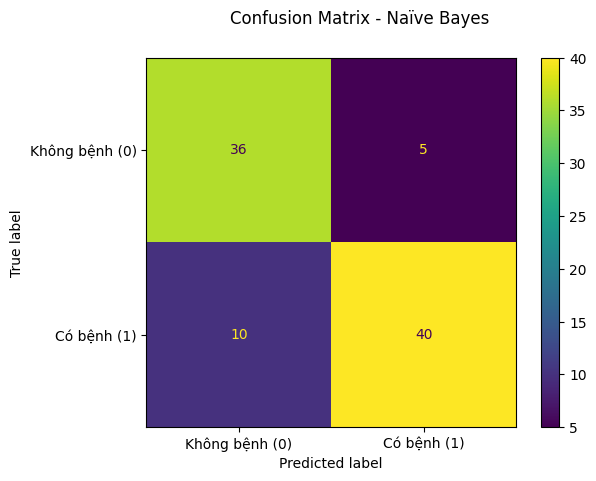

In [11]:
print("Nguyễn Khánh Hà - 6451071022")
nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Classification report - Naïve Bayes:\n")
print(metrics.classification_report(y_test, pred_nb, target_names=["Không bệnh (0)", "Có bệnh (1)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, display_labels=["Không bệnh (0)", "Có bệnh (1)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - Naïve Bayes")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

## Câu 10: So sánh kết quả của các mô hình
Lớp dương là `1` (có bệnh tim).

Nguyễn Khánh Hà - 6451071022
             Accuracy  Precision  Recall  F-measure
Mô hình                                            
ID3            0.6923     0.7391    0.68     0.7083
CART           0.7363     0.7955    0.70     0.7447
Naive Bayes    0.8352     0.8889    0.80     0.8421


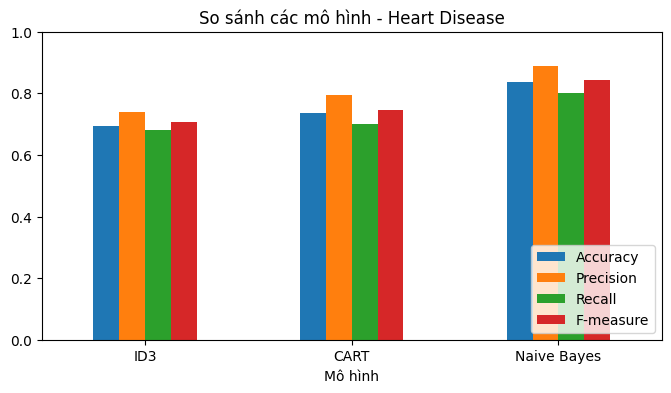


=> Mô hình có Accuracy cao nhất: Naive Bayes (0.8352)


In [12]:
print("Nguyễn Khánh Hà - 6451071022")
preds = {"ID3": pred_id3, "CART": pred_cart, "Naive Bayes": pred_nb}
rows = []
for name, p in preds.items():
    rows.append({
        "Mô hình": name,
        "Accuracy":  metrics.accuracy_score(y_test, p),
        "Precision": metrics.precision_score(y_test, p),
        "Recall":    metrics.recall_score(y_test, p),
        "F-measure": metrics.f1_score(y_test, p),
    })
result = pd.DataFrame(rows).set_index("Mô hình").round(4)
print(result)

result.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("So sánh các mô hình - Heart Disease"); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.show()

best = result["Accuracy"].idxmax()
print(f"\n=> Mô hình có Accuracy cao nhất: {best} ({result.loc[best, 'Accuracy']:.4f})")

**Nhận xét:** Với dữ liệu Heart Disease (303 mẫu, hai lớp khá cân bằng: 138 không bệnh, 165 có bệnh), Naive Bayes cho kết quả tốt nhất với Accuracy 0.8352, Precision 0.8889, Recall 0.80 và F-measure 0.8421. CART đứng thứ hai (Accuracy 0.7363, F-measure 0.7447) và ID3 thấp nhất (Accuracy 0.6923, F-measure 0.7083). Khác với Bài 2 và Bài 4, ở bài này hai cây quyết định không vượt được Naive Bayes vì tập dữ liệu rất nhỏ (chỉ 212 mẫu huấn luyện), cây dễ bị quá khớp với tập huấn luyện, còn Naive Bayes là mô hình đơn giản nên khái quát tốt hơn trên tập kiểm thử chỉ có 91 mẫu. Do tập kiểm thử nhỏ, chênh lệch giữa các mô hình có thể thay đổi khi chia dữ liệu khác đi.